<a href="https://colab.research.google.com/github/naulla/Proyek-ML-Kelompok-1-Medical-Cost-Personal-Asuransi-/blob/main/Medical_Cost_Personal_Kelompok1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1 – Eksplorasi Data
**Proyek Akhir Pembelajaran Mesin (INF62325) · UIN Siber Syekh Nurjati Cirebon · S1 Informatika, Semester V 2026/2027**

**Kelas / Kelompok : 5B/Kelompok 1**

**Anggota : Hanifa Eka Fauziah, Naula Alfiyatul Fauziyyah, Alfiah Lutfi Sabilah**

**Paket dataset : Medical Cost Personal (Asuransi)**

**Berkas yang dipakai : `insurance.csv`**

**Metode kelompok : Klasifikasi (k-NN vs Naive Bayes), target `smoker`**

## Langkah 0 – Baca halaman sumber sebelum menulis kode
Sumber: <https://www.kaggle.com/datasets/mirichoi0218/insurance>

1. **Satu baris data mewakili apa?** satu baris data mewakili satu peserta asuransi, dengan umur, jenis kelamin, indeks massa tubuh, jumlah anak, status merokok, wilayah tempat tinggal, dan biaya klaim tahunan.
2. **Apa arti setiap kolom, dan apa satuannya?**
| Kolom | Arti | Satuan / nilai |
|---|---|---|
| `age` | Umur penerima manfaat utama | tahun (rentang di berkas: 18–64) |
| `sex` | Jenis kelamin pemegang asuransi | `female`, `male` |
| `bmi` | Indeks massa tubuh (rasio berat terhadap tinggi badan) | kg/m² |
| `children` | Jumlah anak/tanggungan yang dicakup asuransi | orang (bulat, 0–5 di berkas) |
| `smoker` | Status merokok | `yes`, `no` |
| `region` | Wilayah tempat tinggal penerima manfaat di AS | `northeast`, `southeast`, `southwest`, `northwest` |
| `charges` | Biaya medis individu yang ditagihkan oleh asuransi kesehatan | dolar AS (periode tidak dinyatakan tegas di sumber; Lampiran B menyebut tahunan, jadi tulis sebagai asumsi) |
3. **Kolom mana yang berupa kode dan di mana daftar artinya?** Tidak ada kolom berupa kode angka. sex, smoker, dan region sudah berupa label teks yang dapat dibaca langsung, children bertipe int64 tetapi berisi hitungan nyata jumlah anak/tanggungan (0–5), sehingga tidak ada kode yang perlu diterjemahkan
4. **Bagaimana data ini dikumpulkan, dan kapan? Apakah ada bagian yang dibangkitkan secara sintetis?** Dataset ini diperoleh dari Kaggle, yang bersumber dari buku Machine Learning with R karya Brett Lantz. Cara pengumpulan dan periode data tidak dijelaskan secara eksplisit. Data ini tidak menggunakan data peserta asuransi nyata.
5. **Apa yang tidak ada di data ini padahal penting untuk pertanyaan Anda?** Kolom smoker hanya berisi yes/no, tidak ada jumlah batang per hari, lama merokok, diagnosis, riwayat penyakit.

## Langkah 1 – Muat data dengan benar

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

CSV_PATH = 'insurance.csv'
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Letakkan insurance.csv di folder yang sama dengan notebook ini.')

df = pd.read_csv(CSV_PATH, na_values=['?', '---', 'unknown', 'NA', 'n/a', ''])
print('Berkas :', CSV_PATH)
print('Bentuk : %d baris x %d kolom' % df.shape)
assert df.shape == (1338, 7), 'Bentuk tidak sesuai tabel paket: periksa berkas/pemisah'

Saving insurance.csv to insurance.csv
Berkas : insurance.csv
Bentuk : 1338 baris x 7 kolom


## Langkah 2 – Potret struktur dan unit analisis

In [ ]:
print(df.head(10))
df.info()

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   flo

In [ ]:
display(df.describe().T)
display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


**Temuan tipe vs arti:** Tidak ada ketidaksesuaian antara tipe dan arti kolom. **Unit analisis:** satu baris = satu peserta asuransi kesehatan (dengan umur, jenis kelamin, BMI, jumlah anak tanggungan, status merokok, wilayah, dan biaya klaim tahunan). Dataset tidak memiliki kolom identifier, sehingga tidak diperlukan agregasi atau penggabungan tabel.

## Langkah 3 – Periksa kebersihan data

### 3a. Nilai hilang

In [ ]:
hilang = pd.DataFrame({'jumlah': df.isna().sum(),
                       'persen': (df.isna().mean() * 100).round(2)}).sort_values('persen', ascending=False)
display(hilang)
print('total sel kosong:', int(df.isna().sum().sum()))

,jumlah,persen
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


total sel kosong: 0


**Temuan:** Tidak ada nilai hilang. Ketujuh kolom terisi penuh (1.338 dari 1.338 baris), dan total sel kosong = 0. **Keputusan:** Tidak ada imputasi atau pembuangan baris karena tidak ada yang perlu ditangani.

### 3b. Data hilang yang tersamar

In [ ]:
for k in ['age', 'bmi', 'charges']:
    print(f'{k:8s} -> bernilai <= 0: {(df[k] <= 0).sum()} baris')
print('children -> bernilai negatif:', (df['children'] < 0).sum(), 'baris')

for k in df.select_dtypes('object').columns:
    print(f'\n{k}:')
    print(df[k].value_counts(dropna=False).to_string())

age      -> bernilai <= 0: 0 baris
bmi      -> bernilai <= 0: 0 baris
charges  -> bernilai <= 0: 0 baris
children -> bernilai negatif: 0 baris

sex:
sex
male      676
female    662

smoker:
smoker
no     1064
yes     274

region:
region
southeast    364
southwest    325
northwest    325
northeast    324


**Temuan:** Nol pada kolom yang tidak mungkin nol tidak ditemukan: age, bmi, dan charges tidak memiliki nilai 0, dan children tidak memiliki nilai negatif. Kolom kategori hanya berisi nilai yang sah (male/female, yes/no, dan empat nama wilayah). Tidak ada penanda teks seperti unknown, ?, atau NA. **Catatan:** children = 0 sah karena berarti peserta tidak punya tanggungan anak. Nilai ini bukan data hilang. **Keputusan:** Tidak ada tindakan. Hasil nol tetap dilaporkan.

### 3c. Duplikat

In [ ]:
print('baris identik seluruhnya:', df.duplicated().sum())
display(df[df.duplicated(keep=False)])

baris identik seluruhnya: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


**Temuan:** Ada 1 baris identik seluruhnya, yaitu indeks 195 dan 581 (usia 19, male, bmi 30,59, 0 anak, non-perokok, northwest, charges 1.639,5631). **Keputusan:** Dibuang 1 baris, karena dataset tidak memiliki id untuk membedakan dua peserta berbeda.

### 3d. Kolom konstan dan identifier

In [ ]:
n = df.nunique()
print(n.to_string())
print('\nkolom konstan        :', list(n[n <= 1].index))
print('hampir unik per baris:', list(n[n > 0.9 * len(df)].index))

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337

kolom konstan        : []
hampir unik per baris: ['charges']


**Temuan:** Tidak ada kolom konstan. Hanya charges yang hampir unik per baris, tetapi bukan identifier. **Keputusan:** Tidak ada kolom yang dibuang pada langkah ini.

### 3e. Nilai mustahil dan pencilan (kolom per kolom, tanpa penghapusan otomatis)

,min,maks,pagar_bawah,pagar_atas,di_luar_pagar
age,18.0000,64.00000,-9.000000,87.000000,0.0
bmi,15.9600,53.13000,13.700000,47.290000,9.0
children,0.0000,5.00000,-3.000000,5.000000,0.0
charges,1121.8739,63770.42801,-13109.150897,34489.350562,139.0


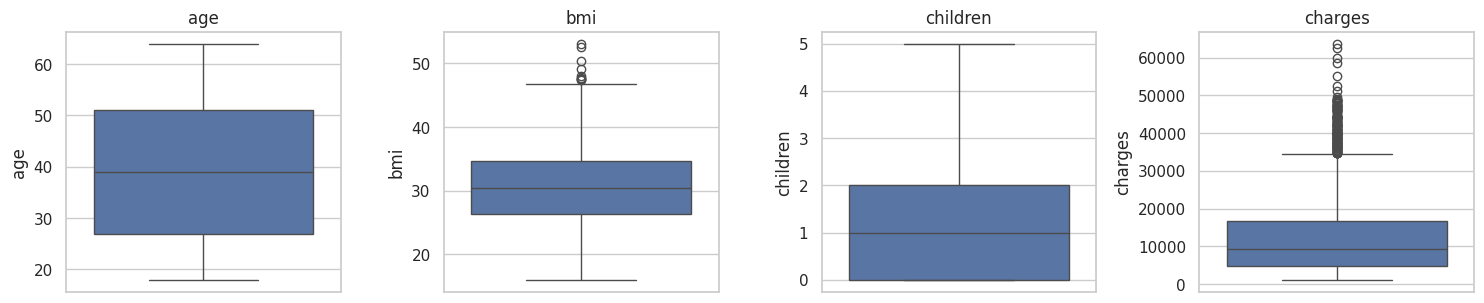

In [ ]:
def ringkas_pencilan(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return pd.Series({'min': s.min(), 'maks': s.max(), 'pagar_bawah': lo, 'pagar_atas': hi,
                      'di_luar_pagar': int(((s < lo) | (s > hi)).sum())})

display(pd.DataFrame({k: ringkas_pencilan(df[k]) for k in ['age', 'bmi', 'children', 'charges']}).T)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, k in zip(ax, ['age', 'bmi', 'children', 'charges']):
    sns.boxplot(y=df[k], ax=a); a.set_title(k)
plt.tight_layout(); plt.show()

**Keputusan:** Tidak ada nilai mustahil. Seluruh pencilan dipertahankan karena bmi setinggi 53 dan klaim sebesar 63.770 USD masih mungkin terjadi pada peserta nyata. Penyaringan IQR serentak tidak dipakai karena akan membuang sekitar 10% data (charges) dan mengubah populasi yang dipelajari.

### 3f. Konsistensi label kategori

In [ ]:
for k in ['sex', 'smoker', 'region']:
    asli = df[k].nunique()
    spasi = (df[k] != df[k].str.strip()).sum()
    df[k] = df[k].str.strip().str.lower()
    bersih = df[k].nunique()
    print(f'{k:7s} unik asli = {asli}, setelah seragam = {bersih}, spasi di tepi = {spasi}')
    print(df[k].value_counts(dropna=False).to_string(), '\n')

sex     unik asli = 2, setelah seragam = 2, spasi di tepi = 0
sex
male      676
female    662 

smoker  unik asli = 2, setelah seragam = 2, spasi di tepi = 0
smoker
no     1064
yes     274 

region  unik asli = 4, setelah seragam = 4, spasi di tepi = 0
region
southeast    364
southwest    325
northwest    325
northeast    324 



**Temuan:** Tidak ada kategori yang tertulis dengan beberapa ejaan, yang berarti label konsisten **Keputusan:** Tidak ada yang perlu diseragamkan.

## Langkah 4 – Pahami variabel target (Cabang B: Klasifikasi)

### Sebaran kelas dan garis dasar

smoker
no     1064
yes     274
Name: count, dtype: int64
smoker
no     79.52
yes    20.48
Name: proportion, dtype: float64

garis dasar kelas mayoritas: 79.52%


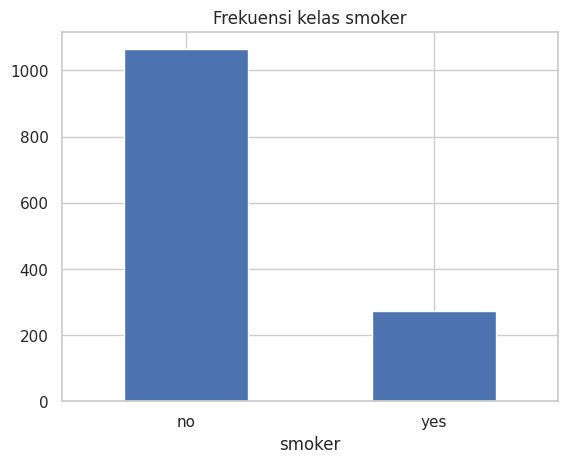

In [ ]:
target_k = 'smoker'
print(df[target_k].value_counts())
print((df[target_k].value_counts(normalize=True) * 100).round(2))
garis_dasar = df[target_k].value_counts(normalize=True).max()
print('\ngaris dasar kelas mayoritas: {:.2%}'.format(garis_dasar))

df[target_k].value_counts().plot.bar(rot=0, title='Frekuensi kelas smoker'); plt.show()

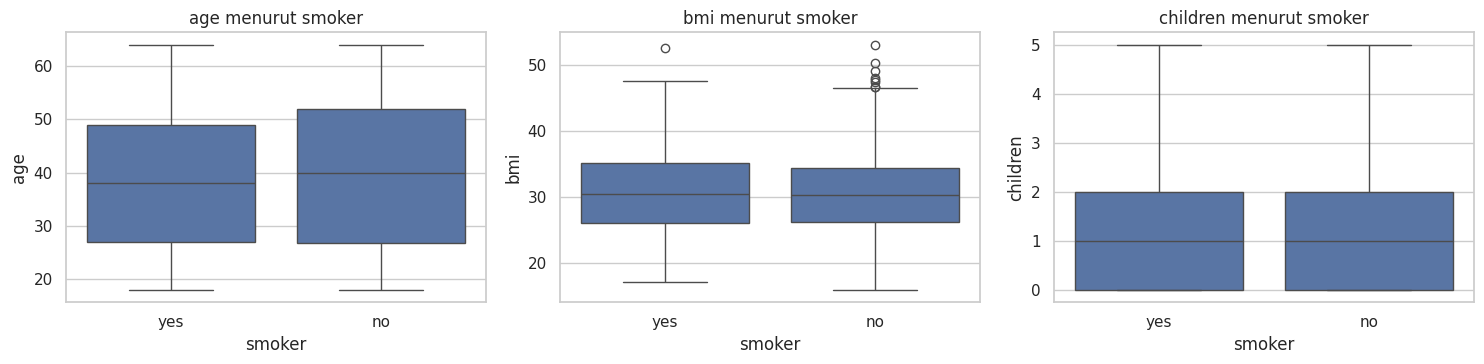


% smoker per sex:
smoker    no   yes
sex               
female  82.6  17.4
male    76.5  23.5

% smoker per region:
smoker       no   yes
region               
northeast  79.3  20.7
northwest  82.2  17.8
southeast  75.0  25.0
southwest  82.2  17.8


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, k in zip(ax, ['age', 'bmi', 'children']):
    sns.boxplot(data=df, x=target_k, y=k, ax=a); a.set_title(f'{k} menurut smoker')
plt.tight_layout(); plt.show()

for k in ['sex', 'region']:
    print(f'\n% smoker per {k}:')
    print((pd.crosstab(df[k], df[target_k], normalize='index') * 100).round(1))

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, StratifiedKFold

yk = (df['smoker'] == 'yes').astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

r = cross_validate(DecisionTreeClassifier(max_depth=1, random_state=42), df[['charges']], yk,
                   cv=cv, scoring=['accuracy', 'f1', 'roc_auc'])
print('charges SAJA (pohon 1 tingkat): akurasi={:.3f}  F1={:.3f}  AUC={:.3f}   | garis dasar={:.3f}'.format(
      r['test_accuracy'].mean(), r['test_f1'].mean(), r['test_roc_auc'].mean(), garis_dasar))

fitur_dasar = pd.get_dummies(df[['age', 'sex', 'bmi', 'children', 'region']], drop_first=True).astype(float)
skenario = {'tanpa charges': fitur_dasar, 'dengan charges': fitur_dasar.assign(charges=df['charges'])}
hasil = []
for nama, X in skenario.items():
    for mn, model in [('k-NN', Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(5))])),
                      ('Naive Bayes', GaussianNB())]:
        r = cross_validate(model, X, yk, cv=cv, scoring=['accuracy', 'f1'])
        hasil.append([nama, mn, r['test_accuracy'].mean(), r['test_f1'].mean()])
display(pd.DataFrame(hasil, columns=['skenario', 'model', 'akurasi', 'F1']).round(3))

charges SAJA (pohon 1 tingkat): akurasi=0.927  F1=0.843  AUC=0.938   | garis dasar=0.795


,skenario,model,akurasi,F1
0,tanpa charges,k-NN,0.764,0.131
1,tanpa charges,Naive Bayes,0.794,0.000
2,dengan charges,k-NN,0.925,0.807
3,dengan charges,Naive Bayes,0.902,0.746


In [ ]:
fitur_num = ['age', 'bmi', 'children', 'charges']
print('rentang (maks - min) per fitur:'); print((df[fitur_num].max() - df[fitur_num].min()).round(1).to_string())

X_skala = fitur_dasar
for nama, model in [('k-NN tanpa penskalaan', KNeighborsClassifier(5)),
                    ('k-NN dengan penskalaan', Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(5))]))]:
    r = cross_validate(model, X_skala, yk, cv=cv, scoring=['accuracy', 'f1'])
    print(f'{nama:24s} akurasi={r["test_accuracy"].mean():.3f}  F1={r["test_f1"].mean():.3f}')

rentang (maks - min) per fitur:
age            46.0
bmi            37.2
children        5.0
charges     62648.6
k-NN tanpa penskalaan    akurasi=0.762  F1=0.078
k-NN dengan penskalaan   akurasi=0.764  F1=0.131


**Temuan (sebaran kelas):** 1.064 peserta bukan perokok (79,52%) dan 274 perokok (20,48%), sekitar empat banding satu. Garis dasar kelas mayoritas = 79,52%.
**Keputusan:** Kedua kelas dipertahankan. Kelas minoritas (274 baris) masih cukup untuk dipelajari dan diuji, dan hanya ada dua kelas sehingga tidak ada yang perlu digabung. Evaluasi memakai recall, precision, F1, dan matriks konfusi dengan pembagian berstrata, karena akurasi saja menyesatkan pada garis dasar 79,52%.

**Temuan (pemisahan kelas oleh fitur):** Perokok 23,5% pada laki-laki dan 17,4% pada perempuan, dan 17,8%–25,0% antarwilayah, dibandingkan rata-rata 20,48%. Fitur selain biaya tampak lemah memisahkan kedua kelas, sehingga model tanpa charges diduga lemah. Dugaan ini terbukti pada validasi silang lima lipatan: k-NN berakurasi 0,764 dengan F1 0,131 (di bawah garis dasar), dan Naive Bayes berakurasi 0,794 dengan F1 0,000, artinya ia selalu menjawab "tidak merokok" dan tidak mendeteksi satu perokok pun.
**Keputusan:** Hasil lemah ini dilaporkan apa adanya sebagai temuan yang sah, tanpa mencari fitur tambahan yang tidak tersedia di data.

**Temuan (kebocoran `charges`):** Ketika charges ditambahkan, k-NN naik menjadi akurasi 0,925 dengan F1 0,807, dan Naive Bayes menjadi akurasi 0,902 dengan F1 0,746. Pohon keputusan satu tingkat yang hanya memakai charges sudah mencapai akurasi 0,927, F1 0,843, dan AUC 0,938, sehingga hampir seluruh kenaikan berasal dari satu kolom itu.
**Keputusan:** charges diperlakukan sebagai fitur yang bocor, karena merupakan pengganti langsung status merokok dan baru diketahui setelah klaim terjadi. Laporan menyajikan dua skenario: skenario utama tanpa charges, dan skenario pembanding dengan charges untuk menunjukkan selisihnya.

**Temuan (penskalaan):** Pada fitur tanpa charges, penskalaan hanya menaikkan akurasi k-NN dari 0,762 ke 0,764 dan F1 dari 0,078 ke 0,131. Efeknya kecil karena age (rentang 46), bmi (37,2), dan children (5) berskala satuan sampai puluhan. Jika charges (rentang 62.648,6) ikut dipakai, kolom itu diduga mendominasi jarak Euclidean tanpa penskalaan.
**Keputusan:** StandardScaler wajib untuk k-NN dan dipasang di dalam Pipeline setelah pembagian data. Naive Bayes tidak memerlukannya, dan perbedaan ini disebut saat membandingkan kedua metode.

## Langkah 5 – Hubungan antar variabel dan pemeriksaan kebocoran

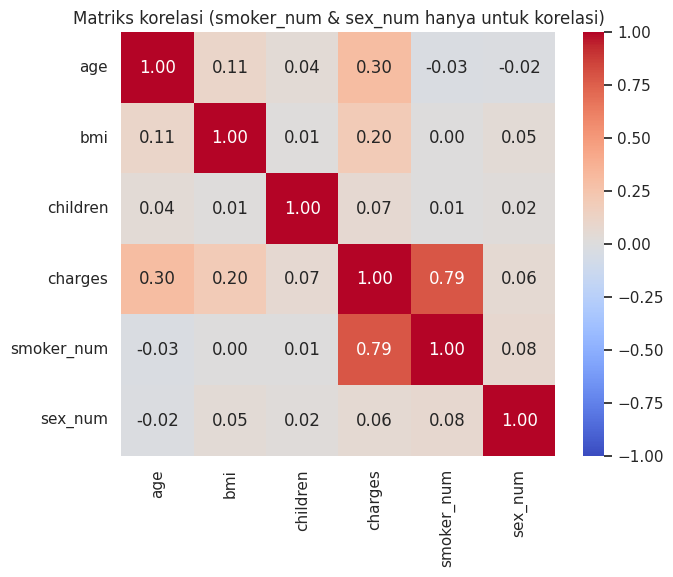

pasangan |r| >  0.8: tidak ada
CURIGAI untuk target smoker_num: tidak ada korelasi > 0.95


In [ ]:
dfn = df.assign(smoker_num=(df['smoker'] == 'yes').astype(int),
                sex_num=(df['sex'] == 'male').astype(int))
kor = dfn.select_dtypes('number').corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(kor, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriks korelasi (smoker_num & sex_num hanya untuk korelasi)'); plt.show()

pasang = [(a, b, round(kor.loc[a, b], 3)) for i, a in enumerate(kor.columns) for b in kor.columns[i+1:] if abs(kor.loc[a, b]) > 0.8]
print('pasangan |r| >  0.8:', pasang if pasang else 'tidak ada')

for tg in ['smoker_num']:
    k = kor[tg].drop(tg).abs()
    print(f'CURIGAI untuk target {tg}:', list(k[k > 0.95].index) or 'tidak ada korelasi > 0.95')

Hasilnya menunjukkan bahwa `charges` hanya berkorelasi kuat dengan `smoker_num` (0,79), artinya perokok cenderung punya biaya medis jauh lebih tinggi. Fitur lain (`age`, `bmi`, `children`, `sex_num`) hampir tidak berkorelasi dengan status merokok (−0,03 sampai 0,08), sehingga lemah untuk membedakan perokok dan bukan perokok. Tidak ada pasangan variabel dengan |r| > 0,8, jadi tidak ada multikolinearitas, dan tidak ada fitur dengan korelasi > 0,95 terhadap target, jadi tidak ada kebocoran ekstrem secara angka. Meski begitu, `charges` tetap dianggap fitur bocor karena nilainya baru diketahui setelah klaim terjadi.

## Langkah 6 – Visualisasi yang menjawab pertanyaan

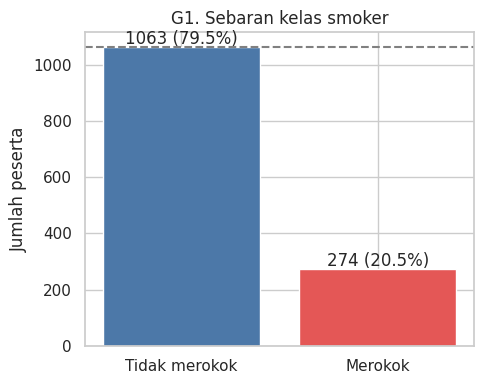

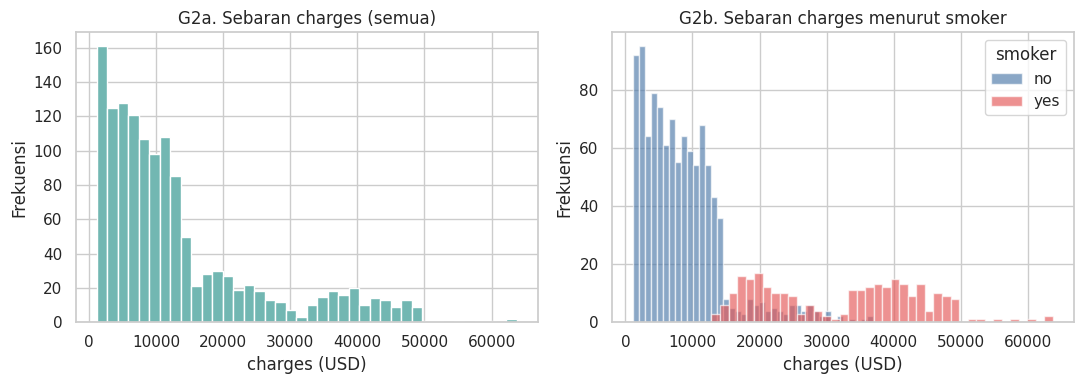

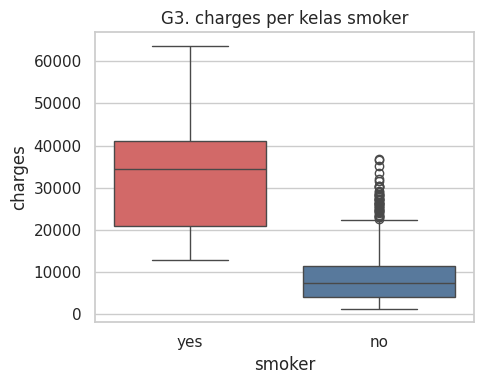

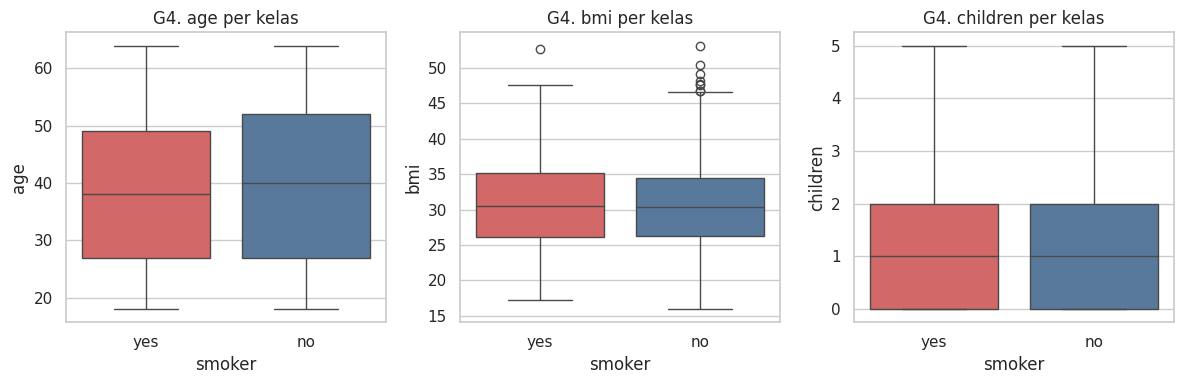

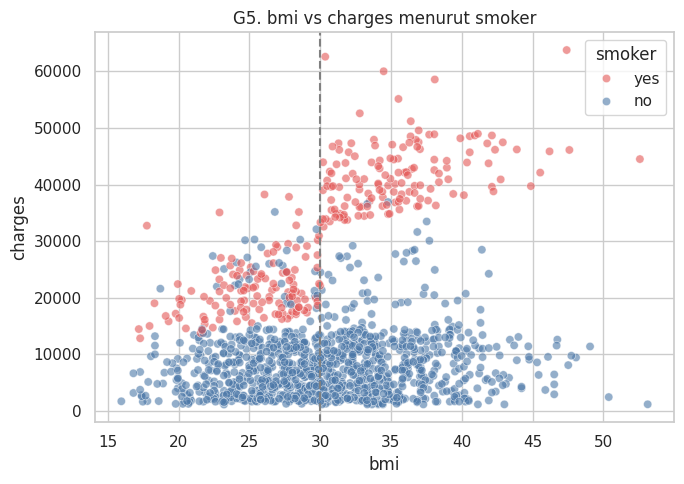

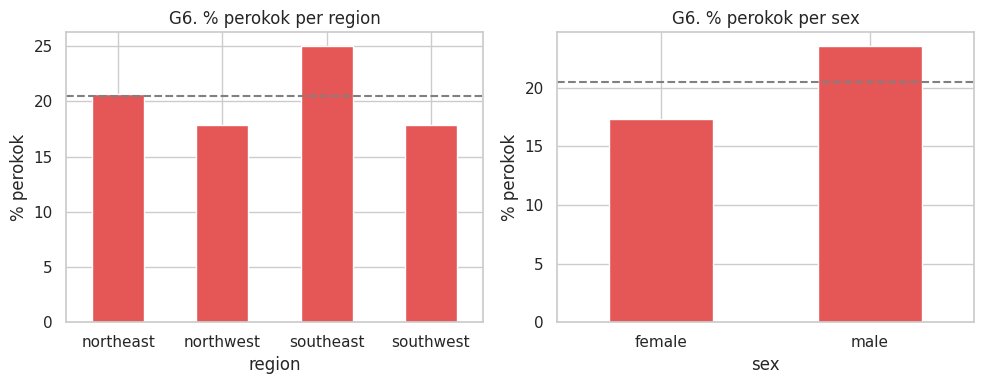

smoker
no      7345.72660
yes    34456.34845
Name: charges, dtype: float64
              age    bmi  children  charges  smoker_num
age         1.000  0.109     0.042    0.298      -0.026
bmi         0.109  1.000     0.013    0.198       0.004
children    0.042  0.013     1.000    0.067       0.007
charges     0.298  0.198     0.067    1.000       0.787
smoker_num -0.026  0.004     0.007    0.787       1.000
perokok bmi<30 vs >=30 median charges 20167.33603 40904.1995
nonsmoker corr age-charges 0.627400223130454
region
northeast    0.207
northwest    0.179
southeast    0.250
southwest    0.178
Name: smoker_num, dtype: float64
sex
female    0.174
male      0.236
Name: smoker_num, dtype: float64


In [ ]:
import os
try:  # paksa grafik tampil di notebook (mengatasi backend 'Agg' yang tersisa dari eksekusi sebelumnya)
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

# ====== UBAH BAGIAN INI SESUAI LINGKUNGAN ANDA ======
# Colab: unggah insurance.csv ke panel Files (ikon folder), lalu pakai:
PATH_CSV = 'insurance.csv'
# Jika memakai Google Drive: '/content/drive/MyDrive/nama_folder/insurance.csv'
FOLDER_GRAFIK = 'grafik'
# =====================================================
os.makedirs(FOLDER_GRAFIK, exist_ok=True)
df = pd.read_csv(PATH_CSV).drop_duplicates().reset_index(drop=True)
df['smoker_num'] = (df.smoker == 'yes').astype(int)
W, C = {'no': '#4C78A8', 'yes': '#E45756'}, None
out = FOLDER_GRAFIK + '/'
def save(n): plt.tight_layout(); plt.savefig(out+n, dpi=150); plt.show()

# G1 sebaran kelas
vc = df.smoker.value_counts()
fig, ax = plt.subplots(figsize=(5,4))
ax.bar(['Tidak merokok','Merokok'], [vc['no'], vc['yes']], color=[W['no'], W['yes']])
for i,v in enumerate([vc['no'], vc['yes']]): ax.text(i, v+10, f'{v} ({v/len(df):.1%})', ha='center')
ax.axhline(vc['no'], ls='--', c='gray'); ax.set_ylabel('Jumlah peserta'); ax.set_title('G1. Sebaran kelas smoker')
save('G1_sebaran_kelas.png')

# G2 histogram charges keseluruhan & per smoker
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].hist(df.charges, bins=40, color='#72B7B2'); ax[0].set_title('G2a. Sebaran charges (semua)')
for k in ['no','yes']: ax[1].hist(df[df.smoker==k].charges, bins=40, alpha=.65, color=W[k], label=k)
ax[1].legend(title='smoker'); ax[1].set_title('G2b. Sebaran charges menurut smoker')
for a in ax: a.set_xlabel('charges (USD)'); a.set_ylabel('Frekuensi')
save('G2_hist_charges.png')

# G3 boxplot charges per kelas
fig, ax = plt.subplots(figsize=(5,4))
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', palette=W, legend=False, ax=ax); ax.set_title('G3. charges per kelas smoker')
save('G3_box_charges.png')

# G4 boxplot fitur numerik per kelas
fig, ax = plt.subplots(1,3, figsize=(12,4))
for a,k in zip(ax, ['age','bmi','children']):
    sns.boxplot(data=df, x='smoker', y=k, hue='smoker', palette=W, legend=False, ax=a); a.set_title(f'G4. {k} per kelas')
save('G4_box_fitur.png')

# G5 scatter bmi vs charges warna smoker
fig, ax = plt.subplots(figsize=(7,5))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette=W, alpha=.6, ax=ax)
ax.axvline(30, ls='--', c='gray'); ax.set_title('G5. bmi vs charges menurut smoker')
save('G5_scatter_bmi_charges.png')

# G6 proporsi perokok per region & sex
fig, ax = plt.subplots(1,2, figsize=(10,4))
for a,k in zip(ax, ['region','sex']):
    (df.groupby(k).smoker_num.mean()*100).plot.bar(ax=a, color='#E45756'); a.set_ylabel('% perokok'); a.set_title(f'G6. % perokok per {k}')
    a.axhline(df.smoker_num.mean()*100, ls='--', c='gray'); a.tick_params(axis='x', rotation=0)
save('G6_proporsi_kategori.png')

print(df.groupby('smoker').charges.median())
print(df[['age','bmi','children','charges','smoker_num']].corr().round(3))
s=df[df.smoker=='yes']; print('perokok bmi<30 vs >=30 median charges', s[s.bmi<30].charges.median(), s[s.bmi>=30].charges.median())
print('nonsmoker corr age-charges', df[df.smoker=='no'][['age','charges']].corr().iloc[0,1])
print(df.groupby('region').smoker_num.mean().round(3)); print(df.groupby('sex').smoker_num.mean().round(3))

**G1. Sebaran kelas smoker**

Apa yang digambar: diagram batang jumlah peserta tidak merokok dan merokok, dengan garis putus-putus setinggi kelas mayoritas.

Cara membaca: tinggi batang menunjukkan jumlah peserta per kelas. Label di atas batang memuat jumlah dan persennya.

Temuan: sekitar 1.063 peserta (79,5%) tidak merokok dan 274 (20,5%) merokok.

Artinya: ini garis dasar Anda. Model yang selalu menjawab “tidak merokok” sudah akurat sekitar 79,5% tanpa belajar apa pun. Model Anda harus dibandingkan dengan angka ini, bukan dengan nol, dan evaluasinya wajib memakai recall, precision, F1, dan matriks konfusi.

**G2. Sebaran charges (G2a keseluruhan, G2b per smoker)**

Apa yang digambar: dua histogram. G2a untuk semua peserta, G2b untuk dua kelas yang ditumpuk dengan warna berbeda.

Cara membaca: sumbu x adalah biaya klaim tahunan (USD), sumbu y adalah banyaknya peserta pada rentang biaya itu. Perhatikan bentuk dan puncaknya.

Temuan: G2a menceng kuat ke kanan (skewness ≈ 1,5), dengan tumpukan di biaya rendah dan ekor panjang sampai sekitar 64 ribu. G2b menunjukkan alasannya: bukan perokok menumpuk di biaya rendah, sedangkan perokok membentuk kelompok tersendiri di biaya tinggi. Ekor panjang itu berasal dari campuran dua kelompok, bukan data rusak.

Artinya: charges bukan satu populasi tunggal. Nanti, jika ada yang memodelkannya dengan regresi linear, kemencengan ini perlu diperhatikan.

**G3. Diagram kotak charges per kelas**

Apa yang digambar: satu diagram kotak untuk bukan perokok dan satu untuk perokok.

Cara membaca: garis tengah kotak adalah median, kotaknya mencakup 50% data tengah (Q1–Q3), dan titik di luar “kumis” adalah titik di luar pagar IQR. Jika dua kotak berjauhan dan tidak bertumpuk, variabel itu memisahkan kelas dengan baik.

Temuan: median bukan perokok sekitar 7.346 dan perokok sekitar 34.456. Biaya perokok paling rendah (±12.829) sudah di atas 90% biaya bukan perokok (±14.341 pada persentil ke-90), jadi tumpang tindihnya kecil.

Artinya: inilah bukti kebocoran data. Biaya klaim adalah akibat dari status merokok, bukan sesuatu yang diketahui lebih dulu. Karena itu charges dikeluarkan dari fitur klasifikasi, atau minimal disajikan dalam dua skenario (dengan dan tanpa charges).

**G4. Diagram kotak age, bmi, children per kelas**

Apa yang digambar: tiga panel diagram kotak, satu per fitur numerik, masing-masing dibagi menurut smoker.

Cara membaca: sama seperti G3. Kotak yang bergeser antar kelas berarti fitur itu membantu memisahkan kelas. Kotak yang sejajar berarti tidak.

Temuan: ketiga pasang kotak hampir sejajar. Rata-rata age 39,4 (bukan perokok) vs 38,5 (perokok), bmi 30,65 vs 30,71, children 1,09 vs 1,11.

Artinya: tidak ada fitur numerik yang memisahkan kelas. Tanpa charges, klasifikasi hampir pasti hanya mendekati garis dasar. Ini temuan yang sah dan layak dilaporkan, bukan tanda Anda keliru.

**G5. Diagram sebar bmi vs charges, diwarnai smoker**

Apa yang digambar: tiap titik adalah satu peserta, dengan bmi di sumbu x dan charges di sumbu y. Warna menandai status merokok, dan garis putus-putus pada bmi = 30 menandai batas obesitas.

Cara membaca: lihat arah dan bentuk gugus titik tiap warna. Garis yang miring ke atas berarti bmi yang lebih tinggi diikuti biaya lebih tinggi.

Temuan: pada bukan perokok, bmi nyaris tidak mengubah biaya. Pada perokok, biaya melonjak ketika bmi ≥ 30: median sekitar 20.167 untuk bmi < 30 dan sekitar 40.904 untuk bmi ≥ 30. Inilah yang membuat tiga gugus biaya di G2.

Artinya: ada interaksi antara smoker dan bmi: pengaruh bmi bergantung pada status merokok. Untuk klasifikasi kelompok Anda, ini konteks mengapa charges begitu kuat. Untuk regresi, interaksi ini harus dimasukkan sebagai suku tersendiri.

**G6. Persentase perokok per region dan per sex**

Apa yang digambar: dua panel batang berisi persentase perokok pada tiap wilayah dan tiap jenis kelamin. Garis putus-putus adalah rata-rata keseluruhan (±20,5%).

Cara membaca: batang yang jauh di atas atau di bawah garis menunjukkan kelompok yang proporsi perokoknya berbeda dari rata-rata.

Temuan: pria 23,6% vs wanita 17,4%. Southeast 25,0%, northeast 20,7%, northwest 17,9%, southwest 17,8%.

Artinya: ada perbedaan, tetapi moderat. Kelompok mana pun masih mayoritas bukan perokok, sehingga sex dan region hanya sedikit membantu memisahkan kelas. Kontribusinya kemungkinan kecil, dan itu perlu dibuktikan lewat model pada Tahap 2.

## Langkah 7 – Catat keputusan dan simpan data bersih

In [ ]:
BUANG_DUPLIKAT = True
DUA_SKENARIO = True

df_bersih = df.copy()
for k in ['sex', 'smoker', 'region']:
    df_bersih[k] = df_bersih[k].str.strip().str.lower()

n_awal = len(df_bersih)
if BUANG_DUPLIKAT:
    df_bersih = df_bersih.drop_duplicates().reset_index(drop=True)
n_dup = n_awal - len(df_bersih)

In [ ]:
keputusan = pd.DataFrame([
    ['Seluruh kolom', 'Sel kosong: %d; nilai <=0 pada age/bmi/charges: %d' % (
        df.isna().sum().sum(), int(sum((df[k] <= 0).sum() for k in ['age', 'bmi', 'charges']))),
     'Tidak ada tindakan',
     'Tidak ada nilai hilang / mustahil yang perlu ditangani', 0],

    ['Baris duplikat', '%d baris identik seluruhnya' % df.duplicated().sum(),
     'Dibuang' if BUANG_DUPLIKAT else 'Dipertahankan',
     'Duplikasi dihapus agar tidak terjadi penghitungan data yang sama secara berulang dan hasil analisis tidak bias.',
     n_dup],

    ['children', 'Bulat 0–5, bertipe int64',
     'Dipertahankan sebagai ordinal/numerik bulat',
     'Jumlah anak merupakan data numerik diskrit yang menunjukkan banyaknya tanggungan. Nilainya tetap dipertahankan karena dapat menjadi informasi dalam analisis.',
     0],

    ['bmi, charges', 'Ada titik di luar pagar IQR (lihat 3e)',
     'Dipertahankan',
     'Pencilan dipertahankan karena masih mungkin merupakan kondisi nyata pada data asuransi, bukan nilai yang mustahil atau kesalahan pencatatan.',
     0],

    ['smoker (target)', 'Kelas tidak seimbang; garis dasar mayoritas (lihat Cabang B)',
     'Dipertahankan dua kelas; evaluasi pakai recall/precision/F1/matriks konfusi',
     'Kedua kelas tetap dipertahankan karena status merokok merupakan target klasifikasi. Meskipun jumlah kelas tidak seimbang, keduanya tetap penting untuk dianalisis.',
     0],

    ['charges (klasifikasi)', 'Mendekati pengganti langsung status smoker (lihat Cabang B)',
     'Dua skenario (dengan & tanpa)',
     'Variabel charges dianalisis dalam dua skenario untuk mengetahui pengaruhnya terhadap hasil klasifikasi. Skenario tanpa charges digunakan untuk menghindari kebocoran informasi karena biaya asuransi berkaitan erat dengan status perokok.',
     0],

], columns=['Kolom / baris', 'Temuan', 'Keputusan', 'Alasan', 'Baris terpengaruh'])

pd.set_option('display.max_colwidth', 80)
display(keputusan)

,Kolom / baris,Temuan,Keputusan,Alasan,Baris terpengaruh
0,Seluruh kolom,Sel kosong: 0; nilai <=0 pada age/bmi/charges: 0,Tidak ada tindakan,Tidak ada nilai hilang / mustahil yang perlu ditangani,0
1,Baris duplikat,1 baris identik seluruhnya,Dibuang,Duplikasi dihapus agar tidak terjadi penghitungan data yang sama secara beru...,1
2,children,"Bulat 0–5, bertipe int64",Dipertahankan sebagai ordinal/numerik bulat,Jumlah anak merupakan data numerik diskrit yang menunjukkan banyaknya tanggu...,0
3,"bmi, charges",Ada titik di luar pagar IQR (lihat 3e),Dipertahankan,Pencilan dipertahankan karena masih mungkin merupakan kondisi nyata pada dat...,0
4,smoker (target),Kelas tidak seimbang; garis dasar mayoritas (lihat Cabang B),Dipertahankan dua kelas; evaluasi pakai recall/precision/F1/matriks konfusi,Kedua kelas tetap dipertahankan karena status merokok merupakan target klasi...,0
5,charges (klasifikasi),Mendekati pengganti langsung status smoker (lihat Cabang B),Dua skenario (dengan & tanpa),Variabel charges dianalisis dalam dua skenario untuk mengetahui pengaruhnya ...,0


In [ ]:
print('ukuran awal  :', df.shape)
print('ukuran bersih:', df_bersih.shape)
df_bersih.to_csv('data_bersih.csv', index=False)
print('tersimpan: data_bersih.csv')

ukuran awal  : (1338, 7)
ukuran bersih: (1337, 7)
tersimpan: data_bersih.csv
